# You roll 6, 5, 5, 3, 2 and keep the two 5’s. What is the probability you will get a Yahtzee in the remaining 2 rolls?

## Simulation

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

rng = np.random.default_rng(seed=2026)

In [3]:
yahtzee_dice = {
    1: (5, 1),
    2: (5, 2),
    3: (5, 3),
    4: (5, 4),
    5: (5, 5),
    6: (5, 6)}

In [48]:
def calculate_exact_probability():
    total_outcomes = 0
    yahtzee_outcomes = 0
dice_outcomes = [1, 2, 3, 4, 5, 6]

def calculate_exact_probability():
    dice_outcomes = list(yahtzee_dice.keys())
    total_prob = 0.0
    
    for d1 in dice_outcomes:
        for d2 in dice_outcomes:
            for d3 in dice_outcomes:
                roll2 = [d1, d2, d3]
                fives_roll2 = roll2.count(yahtzee_dice[5][1])
                needed = 3 - fives_roll2
                
                prob_roll2 = (1 / 6) ** 3
                prob_roll3 = (1 / 6) ** needed
                
total_prob += prob_roll_12 * prob_roll_13

In [120]:
cup = []
for die_face, (count, value) in yahtzee_dice.items():
    cup += [die_face] * count

In [121]:
print("Dice in the cup:", len(cup))
print("Dice contents:", cup)

Dice in the cup: 30
Dice contents: [1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 5, 5, 5, 5, 5, 6, 6, 6, 6, 6]


In [122]:
draws = rng.choice(cup, size=5)
for die in draws:
    print(f"Rolled '{die}'  →  X = {yahtzee_dice[die][1]}")

Rolled '6'  →  X = 6
Rolled '2'  →  X = 2
Rolled '1'  →  X = 1
Rolled '4'  →  X = 4
Rolled '3'  →  X = 3


## Probability Distrabutions

In [126]:
value_counts = {}
for die_face, (count, value) in yahtzee_dice.items():
    value_counts[value] = value_counts.get(value, 0) + count
total_dice = sum(value_counts.values())
dist = pd.DataFrame({
    'x (value)': sorted(value_counts),
    'dice': [value_counts[x] for x in sorted(value_counts)]})

In [127]:
dist['P(X = x)'] = dist['dice'] / total_dice
dist

,x (value),dice,P(X = x)
0,1,5,0.166667
1,2,5,0.166667
2,3,5,0.166667
3,4,5,0.166667
4,5,5,0.166667
5,6,5,0.166667


In [128]:
print("Sum of all probabilities:", round(dist['P(X = x)'].sum(), 4))

Sum of all probabilities: 1.0


## Finding the Distribution

In [129]:
n_draws = 10_000
sim_dice = rng.choice(cup, size=n_draws)
sim_X = np.array([yahtzee_dice[die][1] for die in sim_dice])

In [130]:
sim_props = pd.Series(sim_X).value_counts(normalize=True).sort_index()
compare = dist[['x (value)', 'P(X = x)']].copy()
compare['Simulated proportion'] = compare['x (value)'].map(sim_props).fillna(0)
compare

,x (value),P(X = x),Simulated proportion
0,1,0.166667,0.1660
1,2,0.166667,0.1659
2,3,0.166667,0.1677
3,4,0.166667,0.1665
4,5,0.166667,0.1642
5,6,0.166667,0.1697


## Representing a Distribution

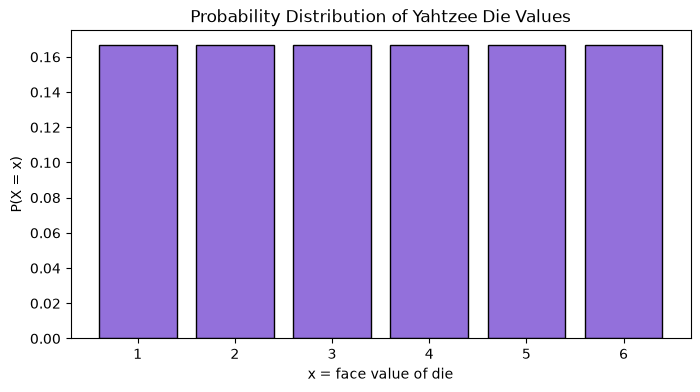

In [131]:
plt.figure(figsize=(8, 4))
plt.bar(dist['x (value)'], dist['P(X = x)'], color='mediumpurple', edgecolor='black')
plt.xlabel('x = face value of die')
plt.ylabel('P(X = x)')
plt.title('Probability Distribution of Yahtzee Die Values')
plt.xticks(dist['x (value)'])
plt.show()

In [132]:
def p(x):
    return value_counts.get(x, 0) / total_dice
print("P(X = 1) =", p(1))
print("P(X = 5) =", p(5))
print("P(X = 7) =", p(7), " ← no die is worth 7 points")

P(X = 1) = 0.16666666666666666
P(X = 5) = 0.16666666666666666
P(X = 7) = 0.0  ← no die is worth 7 points


## Cumulative Probability Distribution

In [133]:
dist['P(X ≤ x)'] = dist['P(X = x)'].cumsum().round(2)
dist

,x (value),dice,P(X = x),P(X ≤ x)
0,1,5,0.166667,0.17
1,2,5,0.166667,0.33
2,3,5,0.166667,0.50
3,4,5,0.166667,0.67
4,5,5,0.166667,0.83
5,6,5,0.166667,1.00


In [134]:
def F(x):
    return round(sum(p(v) for v in value_counts if v <= x), 2)

In [135]:
print("P(X ≤ 1) =", F(1))
print("P(X ≤ 3) =", F(3))
print("P(X > 3) =", round(1 - F(3), 2), " ← use the complement!")

P(X ≤ 1) = 0.17
P(X ≤ 3) = 0.5
P(X > 3) = 0.5  ← use the complement!


## Parameter

In [136]:
for trial in range(1, 6):
    sample = [yahtzee_dice[die][1] for die in rng.choice(cup, size=200)]
    print(f"Simulation {trial}: average die value = {np.mean(sample):.3f}")

Simulation 1: average die value = 3.415
Simulation 2: average die value = 3.635
Simulation 3: average die value = 3.720
Simulation 4: average die value = 3.605
Simulation 5: average die value = 3.540


## Expected Value (Mean)

In [137]:
dist['x · P(x)'] = dist['x (value)'] * dist['P(X = x)']
display(dist[['x (value)', 'P(X = x)', 'x · P(x)']])

mu = dist['x · P(x)'].sum()
print(f"Expected value: μ_X = {mu:.2f} points")

,x (value),P(X = x),x · P(x)
0,1,0.166667,0.166667
1,2,0.166667,0.333333
2,3,0.166667,0.500000
3,4,0.166667,0.666667
4,5,0.166667,0.833333
5,6,0.166667,1.000000


Expected value: μ_X = 3.50 points


In [138]:
running_avg = np.cumsum(sim_X) / np.arange(1, n_draws + 1)

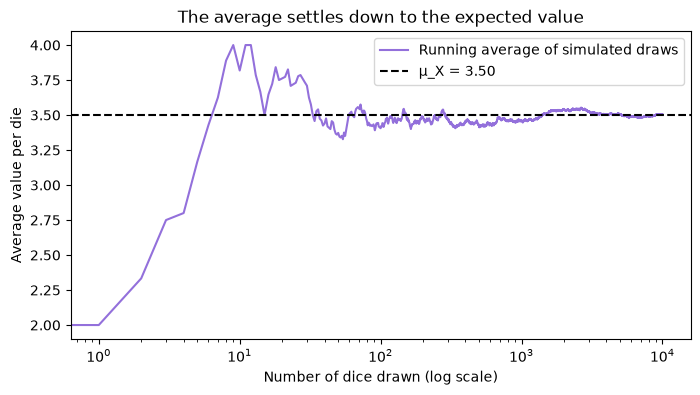

In [139]:
plt.figure(figsize=(8, 4))
plt.plot(running_avg, color='mediumpurple', label='Running average of simulated draws')
plt.axhline(mu, color='black', linestyle='--', label=f'μ_X = {mu:.2f}')
plt.xscale('log')
plt.xlabel('Number of dice drawn (log scale)')
plt.ylabel('Average value per die')
plt.title('The average settles down to the expected value')
plt.legend()
plt.show()

## Standard Deviation

In [140]:
dist['(x − μ)² · P(x)'] = (dist['x (value)'] - mu) ** 2 * dist['P(X = x)']
display(dist[['x (value)', 'P(X = x)', '(x − μ)² · P(x)']].round(4))

,x (value),P(X = x),(x − μ)² · P(x)
0,1,0.1667,1.0417
1,2,0.1667,0.3750
2,3,0.1667,0.0417
3,4,0.1667,0.0417
4,5,0.1667,0.3750
5,6,0.1667,1.0417


In [141]:
variance = dist['(x − μ)² · P(x)'].sum()
sigma = np.sqrt(variance)
print(f"Variance:           σ²_X = {variance:.4f}")
print(f"Standard deviation: σ_X  = {sigma:.2f} points")

Variance:           σ²_X = 2.9167
Standard deviation: σ_X  = 1.71 points


In [142]:
print(f"Simulated mean: {sim_X.mean():.2f}   (parameter μ_X = {mu:.2f})")
print(f"Simulated SD:   {sim_X.std():.2f}   (parameter σ_X = {sigma:.2f})")

Simulated mean: 3.51   (parameter μ_X = 3.50)
Simulated SD:   1.71   (parameter σ_X = 1.71)


## Conclusion

We can see based on the graphs that the running average of dice rolls is between 3.50 and 4.00 and the mean is 3.50 for the Standard Deviation. But on the bar graph for the mean we can see that the probability distrabution is all even for dice face values but on the x=x values we can see that it's distrabution is 0.16. while for the average value per dice is 4.00 so the the average value is more higher than the probability distrabution for the fives obtained. We can see that the standard deviation is more higher since were trying to find the average of rolling two fives rather than the probability distrabution. So there's a higher chance to find the average of the value than the distraubtion since we want to know what it takes to get a Yahtzee with the last two dice. 